In [ ]:
import os
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras import layers, losses, optimizers, models, metrics
from keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from imblearn.combine import SMOTEENN
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
from tensorflow.keras.utils import register_keras_serializable

In [2]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()

In [ ]:
current_dir = Path.cwd()

In [ ]:
train_dir = str(current_dir.parent / 'datasets/train_vae.csv')
valid_dir = str(current_dir.parent / 'datasets/valid_vae.csv')
test_dir = str(current_dir.parent / 'datasets/test_vae.csv')
train_t_dir = str(current_dir.parent / 'datasets/train_embeddings.npy')
valid_t_dir = str(current_dir.parent / 'datasets/valid_embeddings.npy')
test_t_dir = str(current_dir.parent / 'datasets/test_embeddings.npy')
ood_dir = str(current_dir.parent / 'datasets/ood_dataset.csv')
ood_t_dir = str(current_dir.parent / 'datasets/ood_dataset_embeddings.npy')

In [3]:
train = pd.read_csv(train_dir)
valid = pd.read_csv(valid_dir)
test = pd.read_csv(test_dir)
train_t = np.load(train_t_dir)
valid_t = np.load(valid_t_dir)
test_t = np.load(test_t_dir)
ood = pd.read_csv(ood_dir)
ood_t = np.load(ood_t_dir)

train_f = (train.iloc[:,5:-1].copy()).to_numpy()
valid_f = (valid.iloc[:,5:-1].copy()).to_numpy()
test_f = (test.iloc[:,4:-1].copy()).to_numpy()
ood_f = (ood.iloc[:,6:-1].copy()).to_numpy()

# getting the index of each sample to recover the sequence later
d_tr = np.array([i for i in range(len(train))])
d_v = np.array([i for i in range(len(train), len(train) + len(valid))])
d_t = np.array([i for i in range(len(train) + len(valid), len(train) + len(valid) + len(test))])
d_tr = d_tr.reshape(-1,1)
d_v = d_v.reshape(-1,1)
d_t = d_t.reshape(-1,1)
train_f = np.concatenate([train_f, d_tr], axis=1)
valid_f = np.concatenate([valid_f, d_v], axis=1)
test_f = np.concatenate([test_f, d_t], axis=1)
all_sequences = pd.concat([train['sequence'], valid['sequence'], test['sequence']], ignore_index=True)

y = (test.iloc[:,-1].copy()).to_numpy()
y_top = np.zeros(shape=(len(train_t) + len(valid_t),))
y = np.concatenate([y_top, y])
X_emb = np.vstack((train_t, valid_t, test_t))
X_feat = np.vstack((train_f, valid_f, test_f))
X = np.concatenate([X_emb, X_feat], axis=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42, stratify=y_test)


In [4]:
id = pd.concat([train['id_uniprot'], valid['id_uniprot'], test['id_uniprot']], ignore_index=True)

In [5]:
ids = id[X_test[:,-1].copy().astype(int)].copy()

In [6]:
ids.iloc[898], ids.iloc[344]

('BAA36460.1', 'BAB18519.1')

In [ ]:
# getting the test sequences
index = X_test[:,-1].copy().astype(int)
sequences = all_sequences[index].copy()

# dropping the index column
X_test = X_test[:,:-1].copy()
X_train = X_train[:,:-1].copy()
X_valid = X_valid[:,:-1].copy()



smote_enn = SMOTEENN(random_state=42)
X_res, y_res = smote_enn.fit_resample(X=X_train, y=y_train,)

X_train_emb = X_res[:,:1024].copy()
X_train_feat = X_res[:,1024:].copy()
X_valid_emb = X_valid[:,:1024].copy()
X_valid_feat = X_valid[:,1024:].copy()
X_test_emb = X_test[:,:1024].copy()
X_test_feat = X_test[:,1024:].copy()

s_scaler_t = StandardScaler()
s_scaler_f = StandardScaler()
s_scaler_t.fit(X_train_emb)
s_scaler_f.fit(X_train_feat)
X_train_emb = s_scaler_t.transform(X_train_emb)
X_train_feat = s_scaler_f.transform(X_train_feat)
X_valid_emb = s_scaler_t.transform(X_valid_emb)
X_valid_feat = s_scaler_f.transform(X_valid_feat)
X_test_emb = s_scaler_t.transform(X_test_emb)
X_test_feat = s_scaler_f.transform(X_test_feat)
ood_f = s_scaler_f.transform(ood_f)
ood_t = s_scaler_t.transform(ood_t)
X_train = (X_train_emb, X_train_feat)
X_valid = (X_valid_emb, X_valid_feat)
X_test_ = (X_test_emb, X_test_feat)
ood_ = (ood_t, ood_f)

In [6]:
len(set(index)) == len(sequences)

True

In [ ]:
import joblib
joblib.dump(s_scaler_t, str(current_dir.parent / 'models/scaler_t.pkl'))
joblib.dump(s_scaler_f, str(current_dir.parent / 'models/scaler_f.pkl'))
np.save(str(current_dir.parent / 'datasets/pre_processed/train_emb.npy'), X_train_emb)
np.save(str(current_dir.parent / 'datasets/pre_processed/train_feat.npy'), X_train_feat)
np.save(str(current_dir.parent / 'datasets/pre_processed/valid_emb.npy'), X_valid_emb)
np.save(str(current_dir.parent / 'datasets/pre_processed/valid_feat.npy'), X_valid_feat)
np.save(str(current_dir.parent / 'datasets/pre_processed/test_emb.npy'), X_test_emb)
np.save(str(current_dir.parent / 'datasets/pre_processed/test_feat.npy'), X_test_feat)
np.save(str(current_dir.parent / 'datasets/pre_processed/ood_t.npy'), ood_t)
np.save(str(current_dir.parent / 'datasets/pre_processed/ood_f.npy'), ood_f)
np.save(str(current_dir.parent / 'datasets/pre_processed/y_train.npy'), y_res)
np.save(str(current_dir.parent / 'datasets/pre_processed/y_valid.npy'), y_valid)
np.save(str(current_dir.parent / 'datasets/pre_processed/y_test.npy'), y_test)

In [ ]:
X_train_emb = np.load(str(current_dir.parent / 'datasets/pre_processed/train_emb.npy'))
X_train_feat = np.load(str(current_dir.parent / 'datasets/pre_processed/train_feat.npy'))
X_valid_emb = np.load(str(current_dir.parent / 'datasets/pre_processed/valid_emb.npy'))
X_valid_feat = np.load(str(current_dir.parent / 'datasets/pre_processed/valid_feat.npy'))
X_test_emb = np.load(str(current_dir.parent / 'datasets/pre_processed/test_emb.npy'))
X_test_feat = np.load(str(current_dir.parent / 'datasets/pre_processed/test_feat.npy'))
ood_t = np.load(str(current_dir.parent / 'datasets/pre_processed/ood_t.npy'))
ood_f = np.load(str(current_dir.parent / 'datasets/pre_processed/ood_f.npy'))
y_res = np.load(str(current_dir.parent / 'datasets/pre_processed/y_train.npy'))
y_valid = np.load(str(current_dir.parent / 'datasets/pre_processed/y_valid.npy'))
y_test = np.load(str(current_dir.parent / 'datasets/pre_processed/y_test.npy'))
X_train = (X_train_emb, X_train_feat)
X_valid = (X_valid_emb, X_valid_feat)
X_test = (X_test_emb, X_test_feat)
ood = (ood_t, ood_f)

In [3]:
count = {'1': 0, '0': 0}
for i in y_valid:
    if i == 1:
        count['1'] += 1
    else:
        count['0'] += 1
print(count)

{'1': 46, '0': 3033}


In [22]:
test_features = np.concatenate([X_test_emb, X_test_feat], axis=1)
data_to_save = pd.DataFrame(test_features)
sequences = sequences.reset_index(drop=True)
data_to_save['sequence'] = sequences
data_to_save.head(5)

,0,1,2,3,4,5,6,7,8,9,...,1902,1903,1904,1905,1906,1907,1908,1909,1910,sequence
0,-2.540855,1.137460,0.664331,1.186643,-1.630466,1.092405,1.224902,-1.233894,0.087918,1.868736,...,-1.317077,-1.755737,0.591134,0.436091,0.449787,-0.232188,-0.468622,-0.079616,-1.034917,MSAWLDEIRWTADGLVPVVAQEAGTGQVLMVAWMNREALALTAAEG...
1,0.743723,-0.053705,-0.109776,-0.356008,0.319840,-0.114214,0.328397,-0.433188,-0.289205,-0.653954,...,-0.234113,0.017239,-1.705764,-0.357345,-0.038860,0.652336,0.590979,0.361627,0.265347,MVNIGTHVSSSKSLDLVFERGKEVEASSIQFFIRSPRSWAWIERTD...
2,0.539756,-0.670637,-0.215534,-1.067899,0.942063,0.163274,0.486145,-0.531802,-0.814792,-0.587411,...,-0.341473,-0.371362,1.462446,0.436091,-0.123190,0.841223,-0.046833,0.081905,-0.619173,MSEHDRELVSPEAALDDHAVESALRPRTLDEFVGQDRVREQLSLVL...
3,-0.590180,-2.079960,-0.238644,1.319692,-1.549926,-0.097764,-1.569621,-1.390206,1.990164,1.461879,...,-0.662676,-0.965993,-0.365137,0.255261,-0.169397,0.723385,1.047103,1.225751,0.178924,MSWDQVWIDVNVATMDPSISAPYGAITHAAIAVKDGKIAWLGPRSE...
4,0.825649,0.068396,0.406906,-0.658421,0.495966,0.224109,-0.244321,-0.084808,-0.620960,-0.974787,...,-2.107505,-1.182940,0.977932,-0.028161,0.274198,3.227185,0.837519,-0.715373,-2.794135,MAKEPTKAAHPQPEQTKTNHKAHRPVGGYVLAKDPIEINQGRPRTT...


In [ ]:
data_to_save.to_csv(str(current_dir.parent / 'datasets/test_features_sequences.csv'), index=False)

In [4]:
def build_encoder_dnn(input_dim: tuple, units: list[tuple], activation, latent_dim: int, dropout_rate: float = 0.1, dtype: tf.DType = tf.float32):
    first_input = layers.Input(shape=(input_dim[0],), dtype=dtype)
    x = first_input
    for unit in units[0]:
        x = layers.Dense(unit, dtype=dtype)(x)
        x = activation(dtype=dtype)(x)
        x = layers.Dropout(dropout_rate)(x)
    second_input = layers.Input(shape=(input_dim[1],), dtype=dtype)
    y = second_input
    for unit in units[1]:
        y = layers.Dense(unit, dtype=dtype)(y)
        y = activation(dtype=dtype)(y)
        y = layers.Dropout(dropout_rate)(y)
    x = layers.Concatenate()([x, y])
    mean = layers.Dense(latent_dim, dtype=dtype, name='mean')(x)
    log_var = layers.Dense(latent_dim, dtype=dtype, name='log_var')(x)
    encoder = models.Model([first_input, second_input], [mean, log_var], name="encoder")
    return encoder

def build_decoder_dnn(output_dim: tuple, units: list[tuple], activation, latent_dim: int, dropout_rate: float = 0.1, dtype: tf.DType = tf.float32):
    latent_inputs = layers.Input(shape=(latent_dim,), dtype=dtype)
    x = latent_inputs
    for unit in units[0]:
        x = layers.Dense(unit, dtype=dtype)(x)
        x = activation(dtype=dtype)(x)
        x = layers.Dropout(dropout_rate)(x)
    y = latent_inputs
    for unit in units[1]:
        y = layers.Dense(unit, dtype=dtype)(x)
        y = activation(dtype=dtype)(x)
        y = layers.Dropout(dropout_rate)(x)
    first_output = layers.Dense(output_dim[0], activation='linear', dtype=dtype, name='first_output')(x)
    second_output = layers.Dense(output_dim[1], activation='linear', dtype=dtype, name='second_output')(y)
    decoder = models.Model(latent_inputs, [first_output, second_output], name="decoder")
    return decoder

def build_classifier(units: tuple, activation, latent_dim: int, dropout_rate: float = 0.1, dtype: tf.DType = tf.float32):
    input = layers.Input(shape=(latent_dim,))
    x = input
    for unit in units:
        x = layers.Dense(unit, dtype=dtype)(x)
        x = activation(dtype=dtype)(x)
        x = layers.Dropout(dropout_rate)(x)
    output = layers.Dense(1, name='logits_layer')(x)
    p_output = layers.Activation('sigmoid')(output)
    model = models.Model(inputs=input, outputs=p_output, name='classifier')
    return model
    
def sampling_reparameterization(distribution_params):
    mean, log_var = distribution_params
    epsilon = tf.random.normal(shape=tf.shape(mean), mean=0., stddev=1.)
    z = mean + tf.exp(log_var / 2) * epsilon
    return z

In [5]:
protbert_embed_dim = 1024
features_dim = 887
latent_dim = 128
batch_size = 32
epochs = 200
learning_rate = 1e-4
dtype = tf.float32
optimizer = optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0)
kl_weigth = 0.5
mse_emb_weigth = 1.0
mse_feat_weigth = 1.0
bce_weigth = 1.0
enc = build_encoder_dnn((protbert_embed_dim, features_dim), [(768, 512, 256), (512, 256)], layers.LeakyReLU, latent_dim)
dec = build_decoder_dnn((protbert_embed_dim, features_dim), [(256, 512, 768), (256, 512)], layers.LeakyReLU, latent_dim)
classifier = build_classifier((64, 32, 16), layers.LeakyReLU, latent_dim)

In [6]:
def mse_loss(y_true, y_pred):
    r_loss = tf.reduce_mean(tf.square(y_true - y_pred), axis=-1)
    return r_loss

def kl_loss(mean, log_var):
    epsilon = 1e-8
    kl_loss = -0.5 * tf.reduce_mean(1 + log_var - tf.square(mean) - tf.exp(log_var + epsilon), axis = -1)
    return kl_loss

def vae_loss(rec_emb, rec_feat, kl, bce):
    eps = tf.constant(1e-8, dtype=dtype)
    loss = (kl * kl_weigth) + (rec_emb * mse_emb_weigth) + (rec_feat * mse_feat_weigth) + (bce * bce_weigth)
    return loss
    

In [7]:
@register_keras_serializable()
class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, classifier, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder: models.Model = encoder
        self.decoder: models.Model = decoder
        self.classifier: models.Model = classifier
        self.total_loss_tracker = metrics.Mean(name="loss")
        self.bce_loss_tracker = metrics.Mean(name='bce_loss')
        self.reconstruction_loss_emb_tracker = metrics.Mean(
            name="reconstruction_loss_emb"
        )
        self.reconstruction_loss_feat_tracker = metrics.Mean(
            name="reconstruction_loss_feat"
        )
        self.kl_loss_tracker = metrics.Mean(name="kl_loss")
        self.accuracy_tracker = metrics.Accuracy(name='accuracy')
        self.precision_tracker = metrics.Precision(name='precision')
        self.recall_tracker = metrics.Recall(name='recall')
        self.auc_pr_tracker = metrics.AUC(name='auc_pr', curve='PR')
    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_emb_tracker,
            self.reconstruction_loss_feat_tracker,
            self.bce_loss_tracker,
            self.kl_loss_tracker,
            self.accuracy_tracker,
            self.precision_tracker,
            self.recall_tracker,
            self.auc_pr_tracker
        ]


    def call(self, inputs):
        mean, log_var = self.encoder(inputs)
        latent = sampling_reparameterization([mean, log_var])
        pred = self.classifier(latent)
        reconstructed_emb, reconstructed_feat = self.decoder(latent)
        return reconstructed_emb, reconstructed_feat, mean, log_var, pred

    def get_config(self):
        config = super().get_config()
        config.update({
            'encoder': self.encoder,
            'decoder': self.decoder,
            'classifier': self.classifier
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

    def train_step(self, data):
        X, y = data
        with tf.GradientTape() as tape:
            reconstructed_emb, reconstructed_feat, mean, log_var, pred = self(X)
            emb, feat = X
            r_emb_loss = mse_loss(emb, reconstructed_emb)
            r_feat_loss = mse_loss(feat, reconstructed_feat)
            kl = kl_loss(mean, log_var)
            pred = tf.squeeze(pred, axis=-1)
            bce_loss = losses.binary_crossentropy(y, pred)
            loss = vae_loss(r_emb_loss, r_feat_loss, kl, bce_loss)

        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        # Update metrics
        self.total_loss_tracker.update_state(loss)
        self.reconstruction_loss_emb_tracker.update_state(tf.reduce_mean(r_emb_loss))
        self.reconstruction_loss_feat_tracker.update_state(tf.reduce_mean(r_feat_loss))
        self.kl_loss_tracker.update_state(tf.reduce_mean(kl))
        self.bce_loss_tracker.update_state(tf.reduce_mean(bce_loss))
        self.accuracy_tracker.update_state(y, tf.round(pred))
        self.precision_tracker.update_state(y, tf.round(pred))
        self.recall_tracker.update_state(y, tf.round(pred))
        self.auc_pr_tracker.update_state(y, pred)

        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        X, y = data
        reconstructed_emb, reconstructed_feat, mean, log_var, pred = self(X)
        emb, feat = X
        r_emb_loss = mse_loss(emb, reconstructed_emb)
        r_feat_loss = mse_loss(feat, reconstructed_feat)
        kl = kl_loss(mean, log_var)
        pred = tf.squeeze(pred, axis=-1)
        bce_loss = losses.binary_crossentropy(y, pred)
        loss = vae_loss(r_emb_loss, r_feat_loss, kl, bce_loss)

        # Update metrics
        self.total_loss_tracker.update_state(loss)
        self.reconstruction_loss_emb_tracker.update_state(tf.reduce_mean(r_emb_loss))
        self.reconstruction_loss_feat_tracker.update_state(tf.reduce_mean(r_feat_loss))
        self.kl_loss_tracker.update_state(tf.reduce_mean(kl))
        self.bce_loss_tracker.update_state(tf.reduce_mean(bce_loss))
        self.accuracy_tracker.update_state(y, tf.round(pred))
        self.precision_tracker.update_state(y, tf.round(pred))
        self.recall_tracker.update_state(y, tf.round(pred))
        self.auc_pr_tracker.update_state(y, pred)
        return {m.name: m.result() for m in self.metrics}
keras.utils.register_keras_serializable(package='CustomModels', name='VAE')(VAE)

__main__.VAE

In [ ]:
def train(train_data, test_data, epochs, enc, dec, classifier, optimizer):
    vae = VAE(enc, dec, classifier)
    vae.compile(optimizer=optimizer)
    early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    logger = tf.keras.callbacks.CSVLogger(str(current_dir.parent / 'notebooks/history_vae_smoteen.csv'))
    history = vae.fit(train_data[0], train_data[1], epochs=epochs, validation_data=(test_data[0], test_data[1]), callbacks=[early_stopping, logger])
    return history, vae


history, model = train(((X_train_emb, X_train_feat), y_res), ((X_test_emb, X_test_feat), y_test), epochs, enc, dec, classifier, optimizer)

Epoch 1/200
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 113s 69ms/step - accuracy: 0.9909 - auc_pr: 0.9989 - bce_loss: 0.0280 - kl_loss: 0.3642 - loss: 1.3288 - precision: 0.9890 - recall: 0.9932 - reconstruction_loss_emb: 0.3884 - reconstruction_loss_feat: 0.7303 - val_accuracy: 0.9955 - val_auc_pr: 0.9438 - val_bce_loss: 0.0166 - val_kl_loss: 0.3508 - val_loss: 1.5328 - val_precision: 0.7857 - val_recall: 0.9565 - val_reconstruction_loss_emb: 0.3790 - val_reconstruction_loss_feat: 0.9574
Epoch 2/200
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 101s 68ms/step - accuracy: 0.9956 - auc_pr: 0.9992 - bce_loss: 0.0143 - kl_loss: 0.3062 - loss: 1.0146 - precision: 0.9952 - recall: 0.9962 - reconstruction_loss_emb: 0.2581 - reconstruction_loss_feat: 0.5890 - val_accuracy: 0.9906 - val_auc_pr: 0.8381 - val_bce_loss: 0.0389 - val_kl_loss: 0.3394 - val_loss: 1.4220 - val_precision: 0.6197 - val_recall: 0.9565 - val_reconstruction_loss_emb: 0.3298 - val_reconstruction_loss_feat: 0.8796
Epoch 3/200
1478/1478 ━━━━━━━━━━━━━━

In [ ]:
model.encoder.save(str(current_dir.parent / 'models/vae_enc_smoteen.keras'))
model.decoder.save(str(current_dir.parent / 'models/vae_dec_smoteen.keras'))
model.classifier.save(str(current_dir.parent / 'models/vae_classifier_smoteen.keras'))

In [ ]:
enc = keras.models.load_model(str(current_dir.parent / 'models/vae_enc_smoteen.keras'))
dec = keras.models.load_model(str(current_dir.parent / 'models/vae_dec_smoteen.keras'))
classifier = keras.models.load_model(str(current_dir.parent / 'models/vae_classifier_smoteen.keras'))
model = VAE(enc, dec, classifier)

In [9]:
_, _, _, _, pred_train = model((X_train_emb, X_train_feat))
_, _, _, _, pred_valid = model((X_valid_emb, X_valid_feat))
pred_train = pred_train.numpy()
pred_valid = pred_valid.numpy()

In [10]:
pred_train = (pred_train > 0.5).astype(int)
pred_valid = (pred_valid > 0.5).astype(int)

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

Accuracy training: 0.9987
Accuracy test: 0.9990
Precision training: 1.0000
Precision test: 0.9574
Recall training: 0.9974
Recall test: 0.9783
AUC training: 0.9987
AUC test: 0.9888
F1-score training: 0.9987
F1-score test: 0.9677
Clasification report training:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     23023
         1.0       1.00      1.00      1.00     24263

    accuracy                           1.00     47286
   macro avg       1.00      1.00      1.00     47286
weighted avg       1.00      1.00      1.00     47286

Clasification report test:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      3033
         1.0       0.96      0.98      0.97        46

    accuracy                           1.00      3079
   macro avg       0.98      0.99      0.98      3079
weighted avg       1.00      1.00      1.00      3079



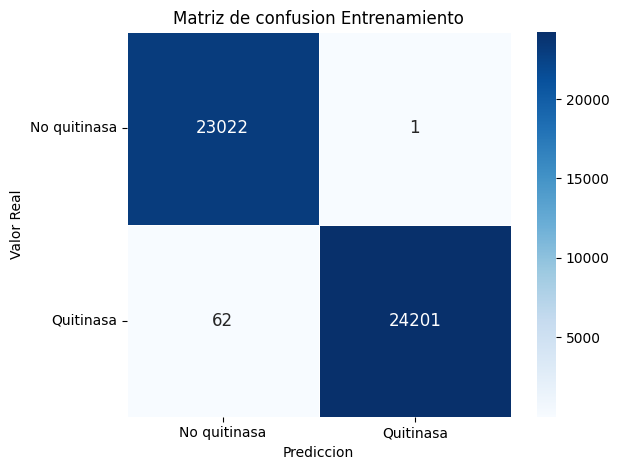

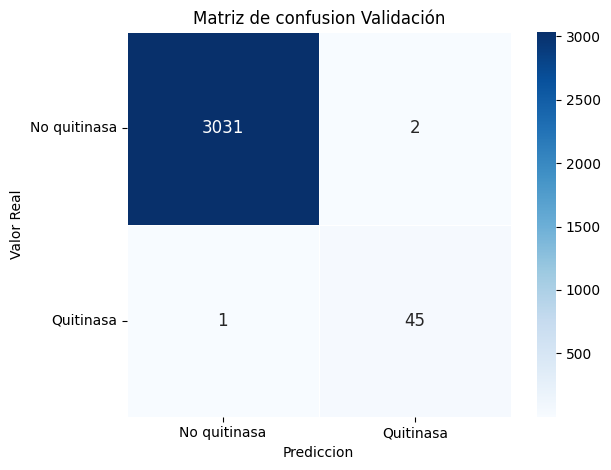

In [12]:
accuracy_t = accuracy_score(y_res, pred_train)
accuracy_v = accuracy_score(y_valid, pred_valid)
precision_t = precision_score(y_res, pred_train)
precision_v = precision_score(y_valid, pred_valid)
recall_t = recall_score(y_res, pred_train)
recall_v = recall_score(y_valid, pred_valid)
roc_auc_t = roc_auc_score(y_res, pred_train)
roc_auc_v = roc_auc_score(y_valid, pred_valid)
f1_t = f1_score(y_res, pred_train)
f1_v = f1_score(y_valid, pred_valid)
conf_matrix_t = confusion_matrix(y_res, pred_train)
conf_matrix_v = confusion_matrix(y_valid, pred_valid)
print(f"Accuracy training: {accuracy_t:.4f}")
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision training: {precision_t:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall training: {recall_t:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC training: {roc_auc_t:.4f}')
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score training: {f1_t:.4f}")
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report training:", classification_report(y_res, pred_train), sep=f'\n')
print("Clasification report test:", classification_report(y_valid, pred_valid), sep=f'\n')
class_labels = ['No quitinasa', 'Quitinasa']
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Entrenamiento')
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Validación')

F1-score test: 0.9778
Clasification report test:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      3033
         1.0       1.00      0.96      0.98        46

    accuracy                           1.00      3079
   macro avg       1.00      0.98      0.99      3079
weighted avg       1.00      1.00      1.00      3079



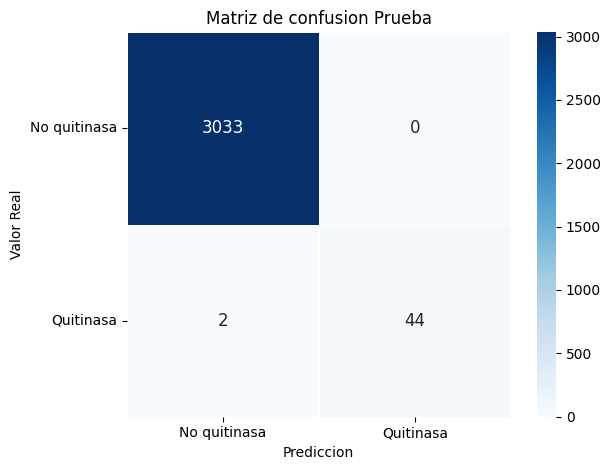

In [13]:
_, _, _, _, pred_test = model((X_test_emb, X_test_feat))
pred_test = pred_test.numpy()
pred_test = (pred_test > 0.5).astype(int)
y_test = y_test.reshape((-1, 1))
f1_t = f1_score(y_test, pred_test)
conf_matrix_t = confusion_matrix(y_test, pred_test)
print(f"F1-score test: {f1_t:.4f}")
print("Clasification report test:", classification_report(y_test, pred_test), sep=f'\n')
class_labels = ['No quitinasa', 'Quitinasa']
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Prueba')

In [ ]:
history = pd.read_csv(str(current_dir.parent / 'notebooks/history_vae_smoteen.csv'))
history.head(10)

,epoch,accuracy,auc_pr,bce_loss,kl_loss,loss,precision,recall,reconstruction_loss_emb,reconstruction_loss_feat,val_accuracy,val_auc_pr,val_bce_loss,val_kl_loss,val_loss,val_precision,val_recall,val_reconstruction_loss_emb,val_reconstruction_loss_feat
0,0,0.990864,0.998886,0.027958,0.364186,1.328821,0.989002,0.993241,0.388438,0.730288,0.995453,0.943801,0.016558,0.350789,1.532801,0.785714,0.956522,0.378975,0.957361
1,1,0.995601,0.999158,0.014343,0.306244,1.014623,0.995183,0.996249,0.258106,0.589040,0.990581,0.838119,0.038870,0.339353,1.422007,0.619718,0.956522,0.329788,0.879591
2,2,0.995347,0.998983,0.016527,0.299972,0.931446,0.994732,0.996208,0.223706,0.541229,0.996752,0.978435,0.010080,0.333087,1.317205,0.846154,0.956522,0.304481,0.832385
3,3,0.995728,0.999525,0.012468,0.294172,0.873472,0.995756,0.995920,0.203296,0.510623,0.996752,0.961170,0.008210,0.334093,1.262630,0.846154,0.956522,0.285072,0.799012
4,4,0.996764,0.999258,0.011785,0.289516,0.832377,0.996499,0.997197,0.188260,0.487575,0.991880,0.832613,0.029826,0.328476,1.239503,0.656716,0.956522,0.270280,0.771878
5,5,0.996743,0.999135,0.011209,0.286331,0.800168,0.996622,0.997033,0.177009,0.468789,0.995778,0.865349,0.022192,0.334278,1.204580,0.800000,0.956522,0.262393,0.749702
6,6,0.997991,0.999659,0.006299,0.283857,0.769588,0.997776,0.998310,0.167919,0.453447,0.996427,0.891481,0.017255,0.331688,1.171487,0.830189,0.956522,0.252221,0.733077
7,7,0.997885,0.999445,0.007206,0.282346,0.749258,0.997529,0.998351,0.160382,0.440501,0.998376,0.937807,0.010898,0.337201,1.145895,0.936170,0.956522,0.244060,0.719439
8,8,0.998329,0.999603,0.006099,0.281800,0.730430,0.998434,0.998310,0.154296,0.429142,0.997402,0.962392,0.007745,0.334922,1.124923,0.895833,0.934783,0.240217,0.706810
9,9,0.998647,0.999685,0.004563,0.282225,0.713700,0.998599,0.998764,0.148891,0.419140,0.997402,0.915852,0.018845,0.335601,1.122296,0.865385,0.978261,0.235386,0.697496


In [16]:
from matplotlib.ticker import MaxNLocator
def plot_charts(history: pd.DataFrame, metrics: tuple[str, str], labels: tuple[str, str]):
    epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

    best_val_loss_idx = history[f'val_{metrics[0]}'].idxmin()
    best_val_acc_idx = history[f'val_{metrics[1]}'].idxmax()

    train_color = '#1f77b4'
    valid_color = '#d62728'
    highlight_color = '#222222'

    sns.set_theme(style='whitegrid', context='paper')
    plt.rcParams.update({
        'font.size': 11,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

    metric_specs = [
        {
            'ax': axes[0],
            'train_key': metrics[0],
            'valid_key': f'val_{metrics[0]}',
            'title': f'{labels[0]} del entrenamiento y validación',
            'ylabel': labels[0],
            'best_idx': best_val_loss_idx,
        },
        {
            'ax': axes[1],
            'train_key': metrics[1],
            'valid_key': f'val_{metrics[1]}',
            'title': f'{labels[1]} del entrenamiento y validación',
            'ylabel': labels[1],
            'best_idx': best_val_acc_idx,
        },
    ]

    for spec in metric_specs:
        ax = spec['ax']
        train_values = history[spec['train_key']].to_numpy()
        valid_values = history[spec['valid_key']].to_numpy()
        best_epoch = int(epochs[spec['best_idx']])
        best_value = valid_values[spec['best_idx']]

        ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
        ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
        ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
        ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
        '''
        ax.annotate(
            f"Época {best_epoch}\n{best_value:.4f}",
            xy=(best_epoch, best_value),
            xytext=(10, 12),
            textcoords='offset points',
            fontsize=9,
            color=highlight_color,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
            arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
        )
        '''

        ax.set_title(spec['title'], pad=10, weight='bold')
        ax.set_xlabel('Época')
        ax.set_ylabel(spec['ylabel'])
        ax.set_xlim(epochs.min(), epochs.max())
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
        ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
        ax.minorticks_on()
        ax.tick_params(axis='both', which='major', length=5, width=0.8)
        ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

    axes[0].text(
        0.02,
        0.98,
        f"{labels[0]} final del entrenamiento: {history[metrics[0]].iloc[-1]:.4f}\n{labels[0]} final validación: {history[f'val_{metrics[0]}'].iloc[-1]:.4f}",
        transform=axes[0].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    axes[1].text(
        0.02,
        0.98,
        f"{labels[1]} final entrenamiento: {history[metrics[1]].iloc[-1]:.4f}\n{labels[1]} final validación: {history[f'val_{metrics[1]}'].iloc[-1]:.4f}",
        transform=axes[1].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
    sns.despine(fig=fig)
    plt.show()

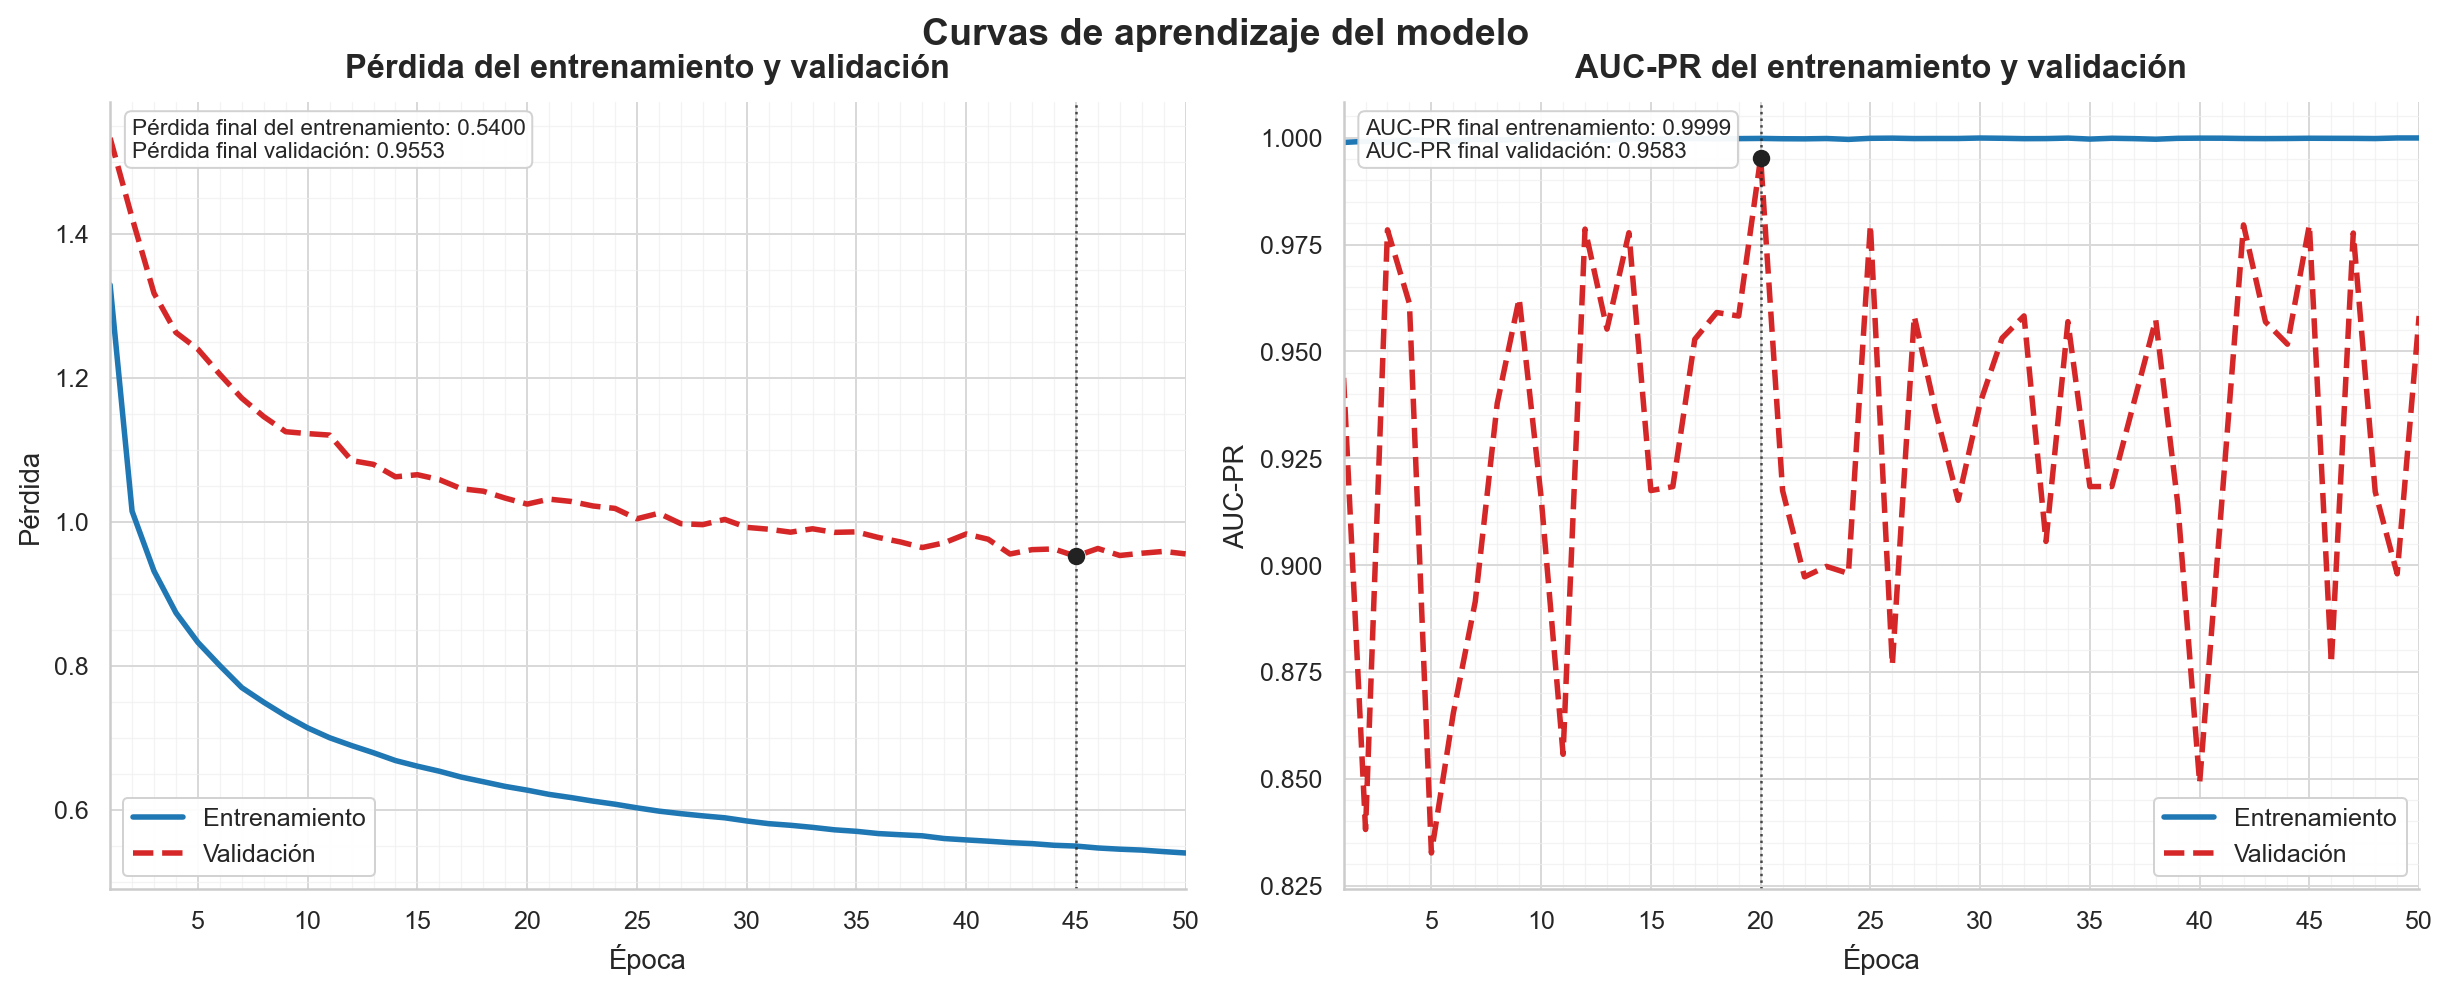

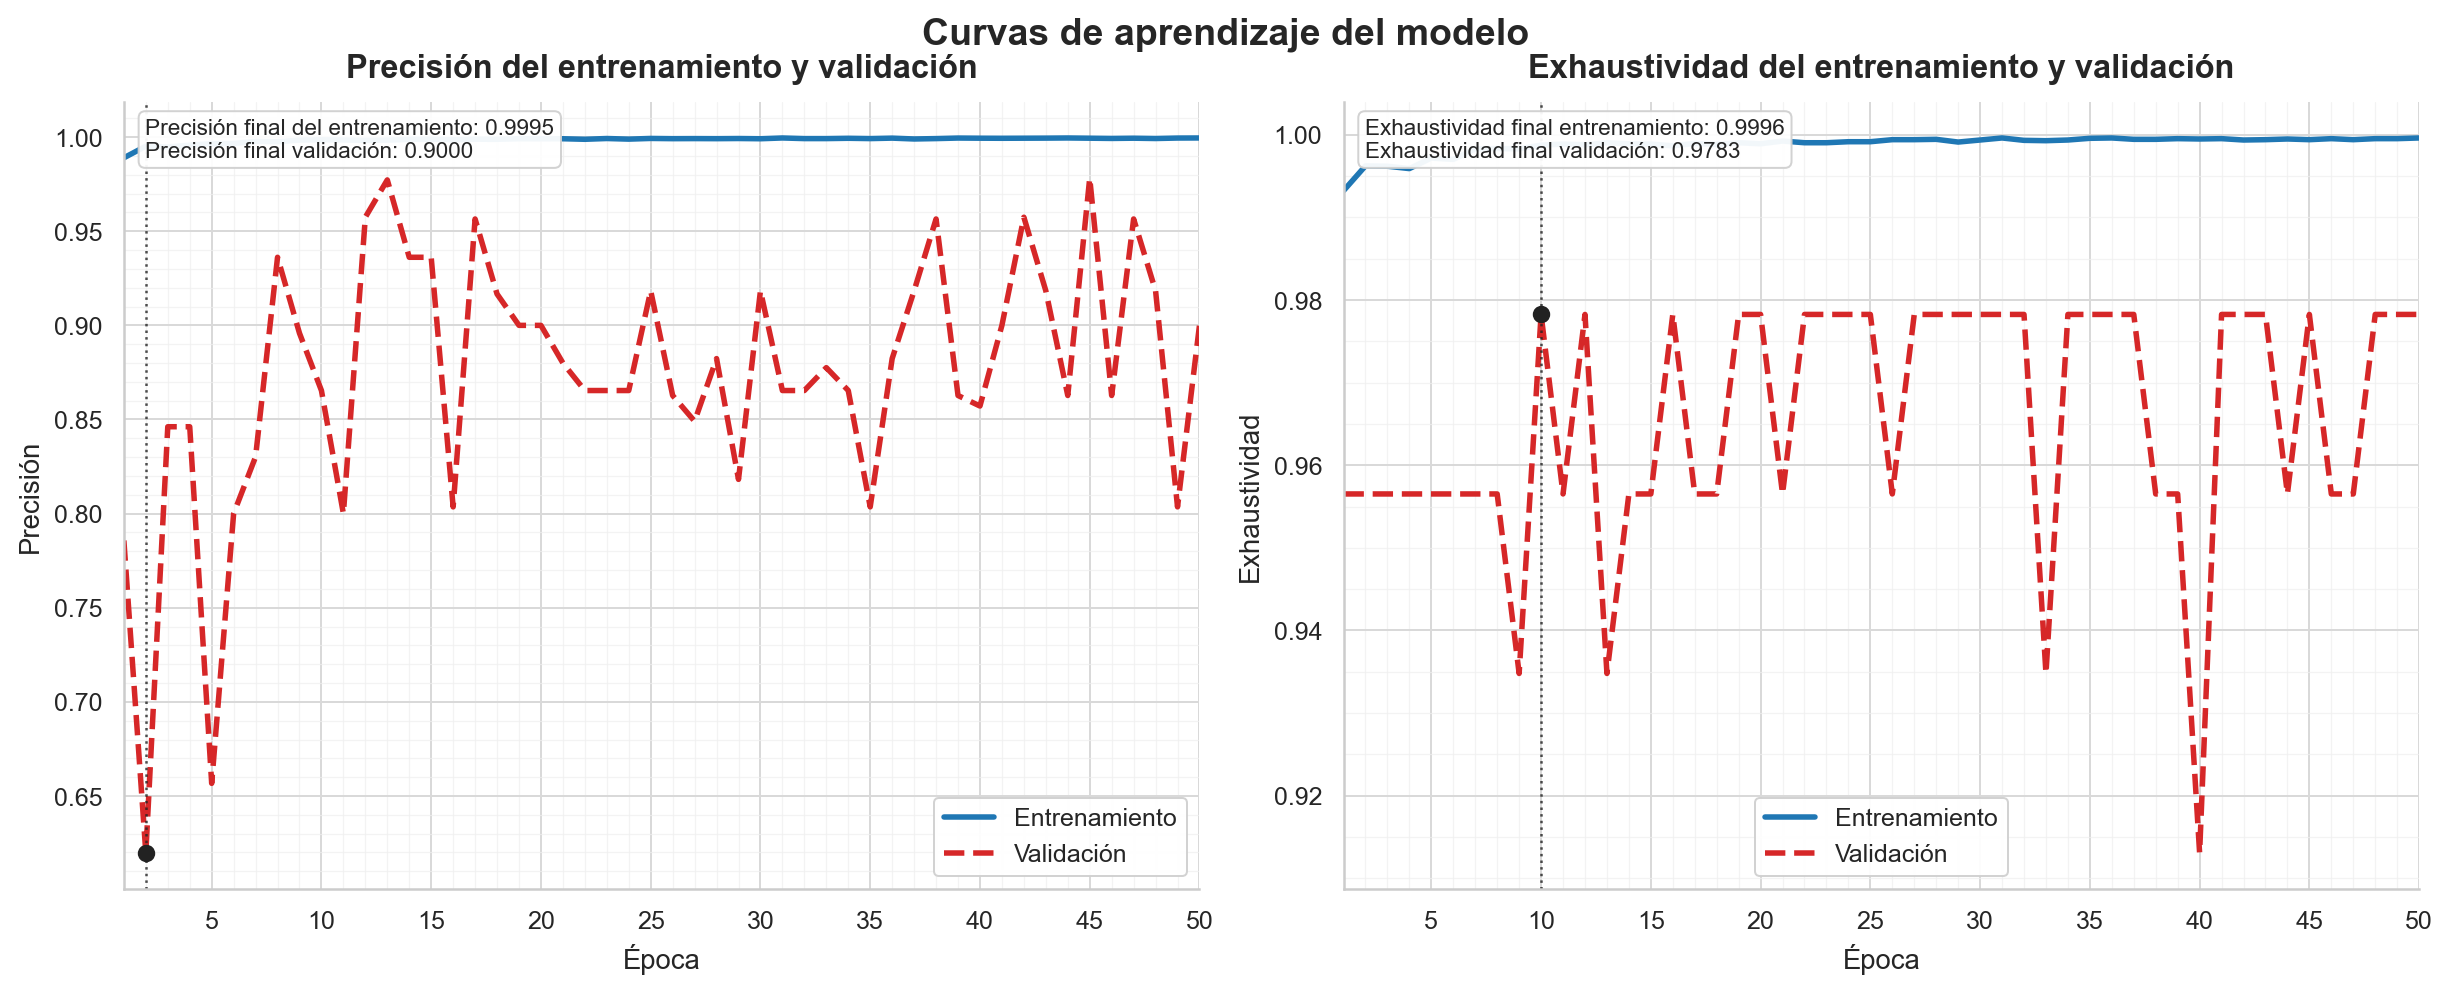

In [17]:
plot_charts(history, ('loss', 'auc_pr'), ('Pérdida', 'AUC-PR'))
plot_charts(history, ('precision', 'recall'), ('Precisión', 'Exhaustividad'))

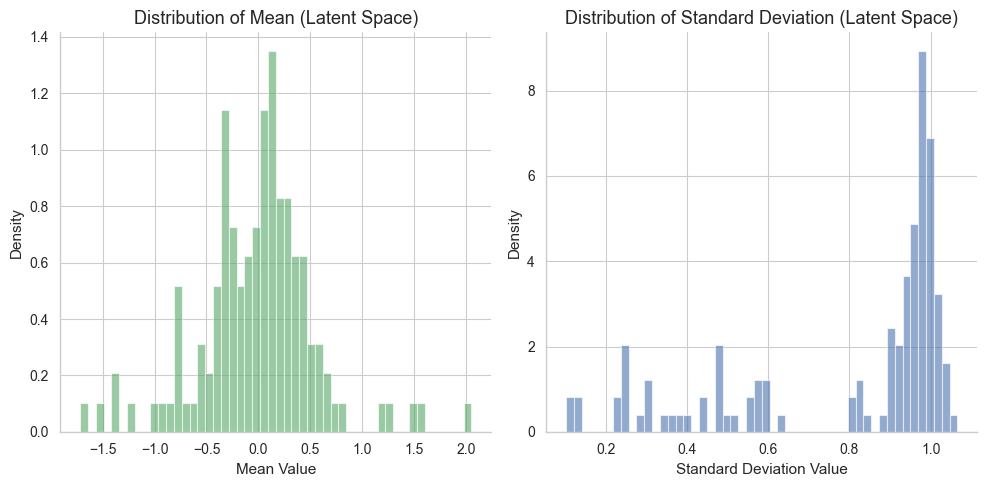

Mean of the latent means for sample 490: -0.0184
Standard deviation of the latent means for sample 490: 0.5575
Mean of the latent standard deviations for sample 490: 0.7971
Standard deviation of the latent standard deviations for sample 490: 0.2773


In [18]:
import matplotlib.pyplot as plt
sample_index = 490
#sample_data = data_reshaped[sample_index:sample_index+1]
sample_data = (X_test_emb[sample_index:sample_index+1], X_test_feat[sample_index:sample_index+1])
# Get the mean and log_var from the encoder
mean, log_var = model.encoder(sample_data)
std_dev = tf.exp(log_var * 0.5)

# Convert tensors to numpy arrays for plotting
mean_np = mean.numpy().flatten()
std_dev_np = std_dev.numpy().flatten()

# Plot the distribution of the mean
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(mean_np, bins=50, density=True, alpha=0.6, color='g')
plt.title('Distribution of Mean (Latent Space)')
plt.xlabel('Mean Value')
plt.ylabel('Density')

# Plot the distribution of the standard deviation
plt.subplot(1, 2, 2)
plt.hist(std_dev_np, bins=50, density=True, alpha=0.6, color='b')
plt.title('Distribution of Standard Deviation (Latent Space)')
plt.xlabel('Standard Deviation Value')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

# You can also display some statistics
print(f"Mean of the latent means for sample {sample_index}: {np.mean(mean_np):.4f}")
print(f"Standard deviation of the latent means for sample {sample_index}: {np.std(mean_np):.4f}")
print(f"Mean of the latent standard deviations for sample {sample_index}: {np.mean(std_dev_np):.4f}")
print(f"Standard deviation of the latent standard deviations for sample {sample_index}: {np.std(std_dev_np):.4f}")